In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from scipy.signal import convolve, fftconvolve

np.random.seed(42)
print("DSP project environment ready.")

DSP project environment ready.


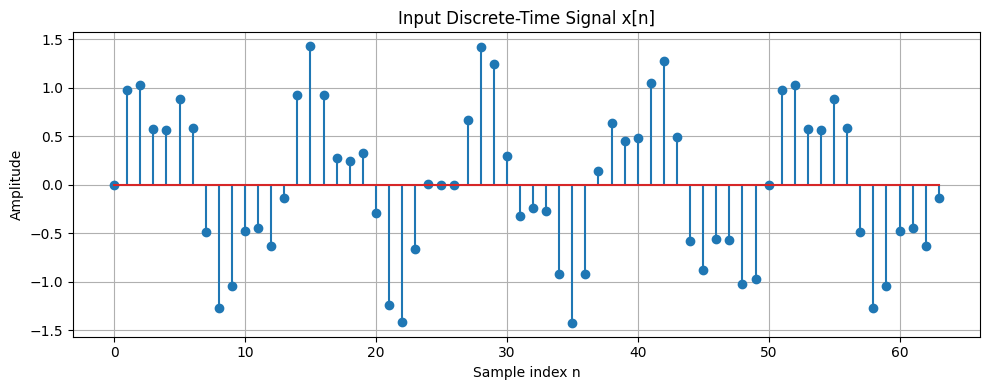

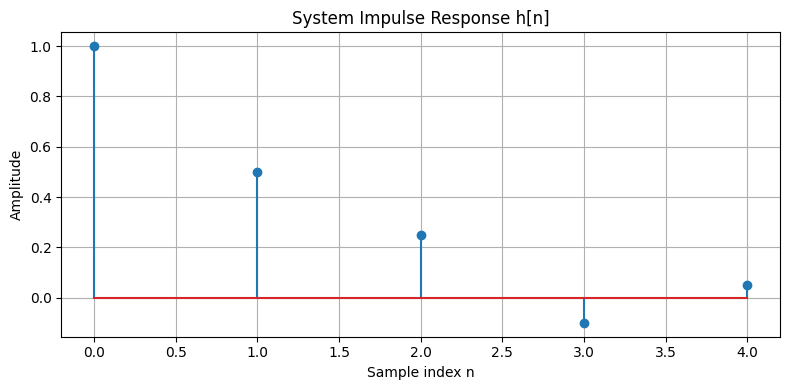

Input length: 64
Impulse response length: 5
Expected linear convolution length: 68


In [30]:
# Input signal: combination of two discrete-time sinusoids
n = np.arange(64)
x = (
    np.sin(2 * np.pi * 0.08 * n)
    + 0.5 * np.sin(2 * np.pi * 0.22 * n)
)

# Impulse response of a simple finite-length system
h = np.array([1.0, 0.5, 0.25, -0.1, 0.05])

plt.figure(figsize=(10, 4))
plt.stem(n, x)
plt.title("Input Discrete-Time Signal x[n]")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.savefig("input_signal.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 4))
plt.stem(np.arange(len(h)), h)
plt.title("System Impulse Response h[n]")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.savefig("impulse_response.png", dpi=200)
plt.show()

print("Input length:", len(x))
print("Impulse response length:", len(h))
print("Expected linear convolution length:", len(x) + len(h) - 1)

In [31]:
def linear_convolution(x, h):
    return np.convolve(x, h, mode="full")


def circular_convolution(x, h, N):
    # FFT-based N-point circular convolution
    X = np.fft.fft(x, n=N)
    H = np.fft.fft(h, n=N)
    return np.real_if_close(np.fft.ifft(X * H))


y_linear = linear_convolution(x, h)

# Deliberately too short: this produces circular wraparound
y_circular_short = circular_convolution(x, h, N=len(x))

# Correctly padded: N must be at least len(x) + len(h) - 1
N_required = len(x) + len(h) - 1
y_circular_padded = circular_convolution(x, h, N=N_required)

print("Linear output length:", len(y_linear))
print("Short circular output length:", len(y_circular_short))
print("Padded circular output length:", len(y_circular_padded))

Linear output length: 68
Short circular output length: 64
Padded circular output length: 68


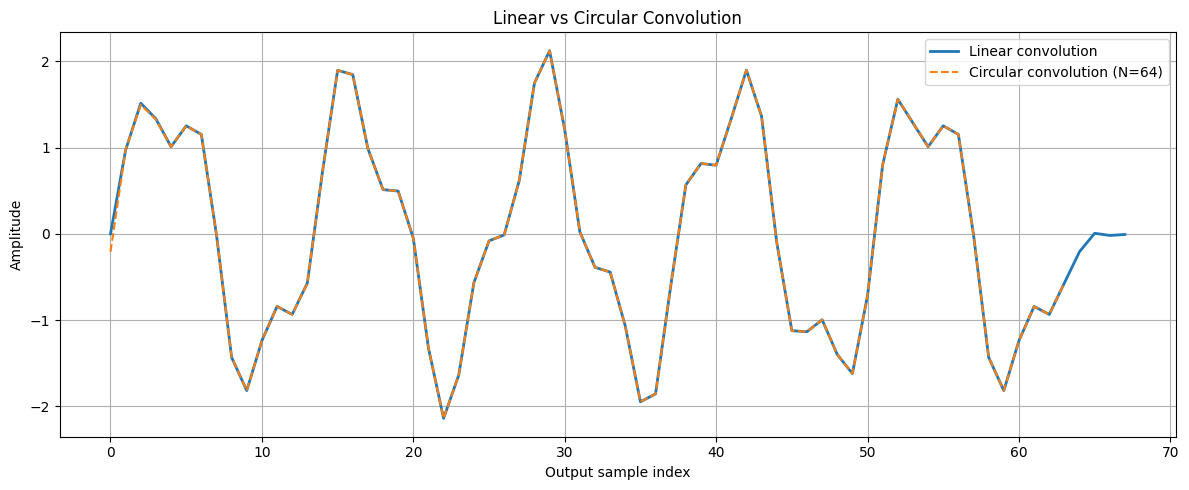

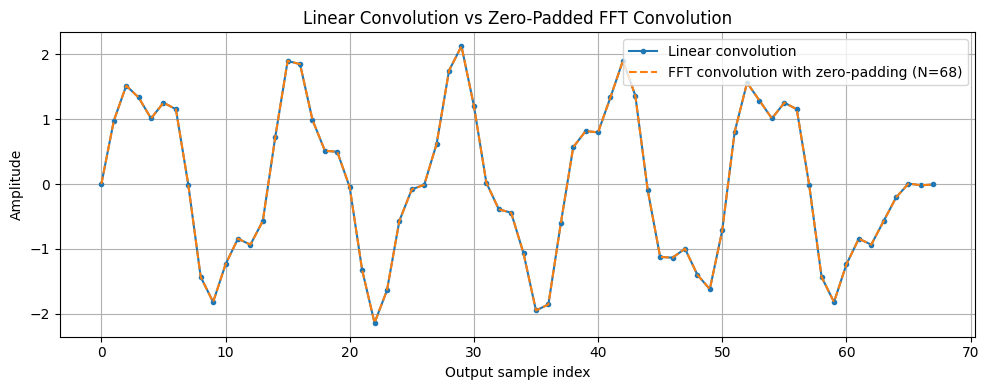

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(y_linear, label="Linear convolution", linewidth=2)
plt.plot(
    np.arange(len(y_circular_short)),
    y_circular_short,
    "--",
    label="Circular convolution (N=64)"
)
plt.title("Linear vs Circular Convolution")
plt.xlabel("Output sample index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("linear_vs_circular.png", dpi=200)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(
    y_linear,
    label="Linear convolution",
    marker="o",
    markersize=3
)
plt.plot(
    y_circular_padded,
    "--",
    label=f"FFT convolution with zero-padding (N={N_required})"
)
plt.title("Linear Convolution vs Zero-Padded FFT Convolution")
plt.xlabel("Output sample index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("zero_padding_comparison.png", dpi=200)
plt.show()

In [33]:
def metrics(reference, estimate):
    error = reference - estimate
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    max_error = np.max(np.abs(error))

    return {
        "MSE": mse,
        "RMSE": rmse,
        "Maximum absolute error": max_error
    }


# Compare outputs over the common 64 samples for short circular convolution
short_metrics = metrics(
    y_linear[:len(y_circular_short)],
    y_circular_short
)

padded_metrics = metrics(y_linear, y_circular_padded)

comparison = pd.DataFrame([
    {
        "Method": "Direct linear convolution",
        **metrics(y_linear, y_linear)
    },
    {
        "Method": "Circular convolution, N=64",
        **short_metrics
    },
    {
        "Method": f"FFT convolution, N={N_required}",
        **padded_metrics
    }
])

display(comparison.round(10))
comparison.to_csv("convolution_comparison.csv", index=False)

,Method,MSE,RMSE,Maximum absolute error
0,Direct linear convolution,0.000000,0.0000,0.000000
1,"Circular convolution, N=64",0.000671,0.0259,0.206179
2,"FFT convolution, N=68",0.000000,0.0000,0.000000


,FFT length N,Required length,Zero-padding sufficient,MSE,RMSE,Maximum absolute error
0,64,68,False,0.000671,0.0259,0.206179
1,68,68,True,0.000000,0.0000,0.000000
2,79,68,True,0.000000,0.0000,0.000000
3,96,68,True,0.000000,0.0000,0.000000
4,128,68,True,0.000000,0.0000,0.000000


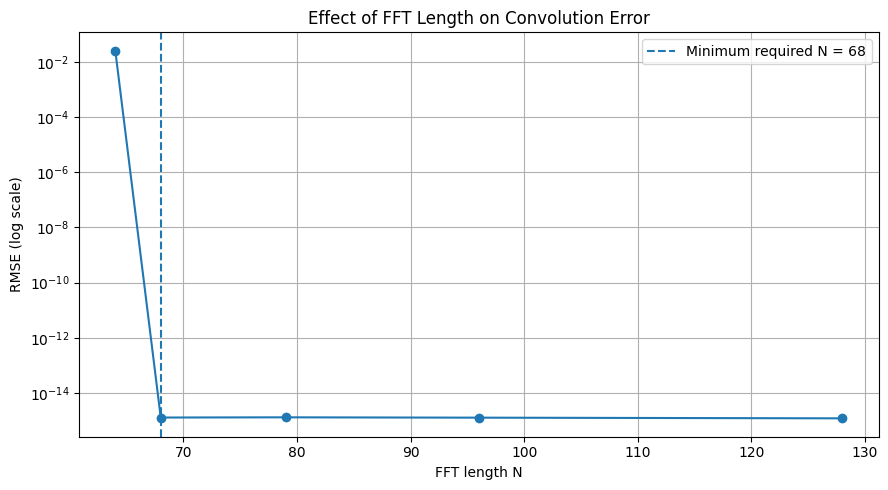

In [34]:
experiment_rows = []
linear_length = len(x) + len(h) - 1

for N in [32, 48, 64, 68, 79, 96, 128]:
    if N < max(len(x), len(h)):
        continue

    y_fft = circular_convolution(x, h, N)

    # Only an N-point output is produced. Compare against
    # the reference samples available at those indices.
    ref = y_linear[:N]
    estimated = y_fft[:len(ref)]

    result = metrics(ref, estimated)

    experiment_rows.append({
        "FFT length N": N,
        "Required length": linear_length,
        "Zero-padding sufficient": N >= linear_length,
        "MSE": result["MSE"],
        "RMSE": result["RMSE"],
        "Maximum absolute error": result["Maximum absolute error"]
    })

fft_results = pd.DataFrame(experiment_rows)
display(fft_results.round(8))
fft_results.to_csv("fft_length_experiments.csv", index=False)

plt.figure(figsize=(9, 5))
plt.semilogy(
    fft_results["FFT length N"],
    fft_results["RMSE"] + 1e-15,
    marker="o"
)
plt.axvline(
    linear_length,
    linestyle="--",
    label=f"Minimum required N = {linear_length}"
)
plt.xlabel("FFT length N")
plt.ylabel("RMSE (log scale)")
plt.title("Effect of FFT Length on Convolution Error")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("fft_length_error.png", dpi=200)
plt.show()

,Input length,Impulse response length,Direct convolution time (ms),FFT convolution time (ms)
0,64,31,0.02306,0.16745
1,256,31,0.03924,0.12414
2,1024,31,0.02909,0.08543
3,4096,31,0.09216,0.14390


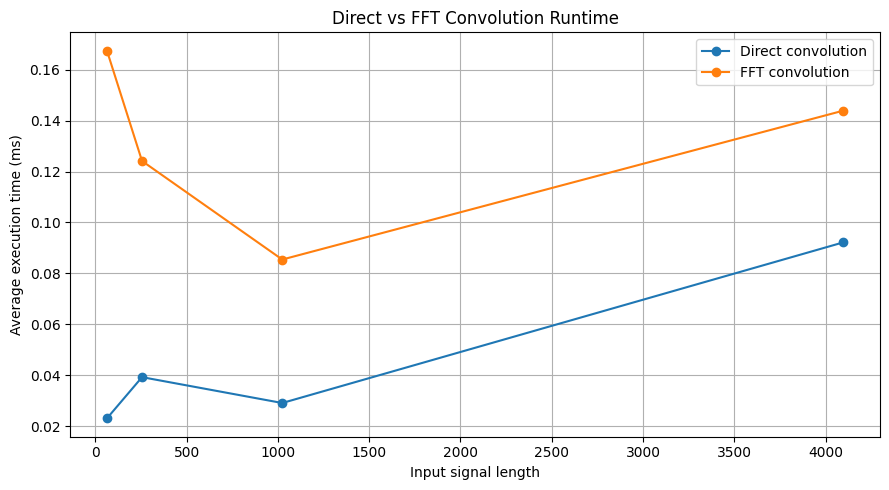

In [35]:
# Compare direct convolution and FFT-based linear convolution
rng = np.random.default_rng(42)
timing_rows = []

for L in [64, 256, 1024, 4096]:
    a = rng.normal(size=L)
    b = rng.normal(size=31)

    # Warm-up
    convolve(a, b, method="direct")
    fftconvolve(a, b, mode="full")

    repetitions = 30 if L <= 1024 else 10

    start = time.perf_counter()
    for _ in range(repetitions):
        convolve(a, b, method="direct")
    direct_time = (time.perf_counter() - start) / repetitions

    start = time.perf_counter()
    for _ in range(repetitions):
        fftconvolve(a, b, mode="full")
    fft_time = (time.perf_counter() - start) / repetitions

    timing_rows.append({
        "Input length": L,
        "Impulse response length": len(b),
        "Direct convolution time (ms)": direct_time * 1000,
        "FFT convolution time (ms)": fft_time * 1000
    })

timing_results = pd.DataFrame(timing_rows)
display(timing_results.round(5))
timing_results.to_csv("convolution_timing.csv", index=False)

plt.figure(figsize=(9, 5))
plt.plot(
    timing_results["Input length"],
    timing_results["Direct convolution time (ms)"],
    marker="o",
    label="Direct convolution"
)
plt.plot(
    timing_results["Input length"],
    timing_results["FFT convolution time (ms)"],
    marker="o",
    label="FFT convolution"
)
plt.xlabel("Input signal length")
plt.ylabel("Average execution time (ms)")
plt.title("Direct vs FFT Convolution Runtime")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("runtime_comparison.png", dpi=200)
plt.show()

In [36]:
from google.colab import files

files_to_download = [
    "convolution_comparison.csv",
    "fft_length_experiments.csv",
    "convolution_timing.csv",
    "input_signal.png",
    "impulse_response.png",
    "linear_vs_circular.png",
    "zero_padding_comparison.png",
    "fft_length_error.png",
    "runtime_comparison.png"
]

for filename in files_to_download:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>